# Handwritten Digit Recognition using CNN



## 1. Import libraries

In [1]:
import numpy as np  # Linear algebra and array manipulations
import matplotlib.pyplot as plt  # Data visualization and plotting
import tensorflow as tf  # Deep learning framework
from tensorflow.keras import layers, models  # High-level neural networks API
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # Evaluation metrics

# Print runtime environment info to verify dependencies
print('TensorFlow version:', tf.__version__)
print('GPU available:', bool(tf.config.list_physical_devices('GPU')))

TensorFlow version: 2.21.0
GPU available: True


## 2. Load the MNIST dataset
MNIST contains 28×28 grayscale images of handwritten digits. Pixel values range from 0 to 255.

In [2]:
# Load the built-in MNIST dataset from Keras
# It returns training data (60k samples) and testing data (10k samples)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Display the shapes of datasets and the targets
print('Training images:', x_train.shape)  # Shape: (60000, 28, 28)
print('Testing images:', x_test.shape)    # Shape: (10000, 28, 28)
print('Classes:', np.unique(y_train))     # Digits from 0 to 9

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Classes: [0 1 2 3 4 5 6 7 8 9]


## 3. Explore sample images

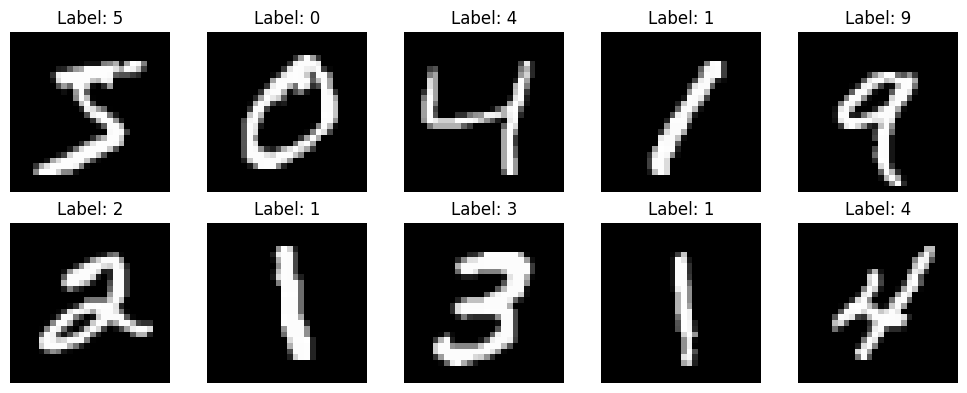

In [3]:
# Visualize the first 10 training images to inspect the dataset
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)  # Create a grid of 2 rows and 5 columns
    plt.imshow(x_train[i], cmap='gray')  # Show image in grayscale
    plt.title(f'Label: {y_train[i]}')  # Title with ground-truth label
    plt.axis('off')  # Hide axis ticks
plt.tight_layout()  # Adjust spacing between plots
plt.show()

## 4. Preprocess the images
Normalize pixels to 0–1 and add a channel dimension because CNN expects image tensors in the format `(height, width, channels)`.

In [4]:
# Step 1: Normalize pixel values from [0, 255] range to [0, 1] for better neural network convergence
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Step 2: Reshape images from (28, 28) to (28, 28, 1)
# Convolutional Neural Networks (CNNs) require a explicit channel dimension (1 for grayscale)
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print('Processed training shape:', x_train.shape)
print('Processed testing shape:', x_test.shape)

Processed training shape: (60000, 28, 28, 1)
Processed testing shape: (10000, 28, 28, 1)


## 5. Build the CNN model
- **Conv2D:** learns visual patterns such as edges and curves.
- **MaxPooling2D:** reduces feature-map size.
- **Flatten:** converts feature maps into a vector.
- **Dense:** learns classification patterns.
- **Softmax:** outputs probabilities for the 10 digits.

In [5]:
# Define the Sequential neural network architecture
model = models.Sequential([
    # Input layer specifying the expected image size: 28x28 with 1 color channel
    layers.Input(shape=(28, 28, 1)),

    # First Convolutional Layer: Extracts 32 low-level features using 3x3 filters
    layers.Conv2D(32, (3, 3), activation='relu'),
    # First Max Pooling: Reduces spatial dimensions by half (from 26x26 to 13x13)
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer: Extracts 64 complex features
    layers.Conv2D(64, (3, 3), activation='relu'),
    # Second Max Pooling: Redues dimensions again (from 11x11 to 5x5)
    layers.MaxPooling2D((2, 2)),

    # Flatten Layer: Flattens the 3D feature maps into a 1D vector (5*5*64 = 1600 elements)
    layers.Flatten(),

    # Fully Connected Layer with 64 neurons to learn global relations
    layers.Dense(64, activation='relu'),

    # Dropout Layer: Randomly deactivates 30% of neurons to prevent overfitting
    layers.Dropout(0.3),

    # Output Layer: 10 neurons (one for each digit) using softmax activation for probability distribution
    layers.Dense(10, activation='softmax')
])

# Compile the model with loss, optimizer, and metrics
model.compile(optimizer='adam',  # Adam optimizer for efficient gradient descent
              loss='sparse_categorical_crossentropy',  # Suitable for integer targets
              metrics=['accuracy'])  # Evaluate performance using accuracy

# Display the model summary (layers, output shapes, parameters)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model
The notebook uses a validation split to monitor performance on data not used for weight updates.

In [6]:
# Train the model using the training subset
history = model.fit(
    x_train, y_train,
    epochs=5,               # Loop over the entire dataset 5 times
    batch_size=128,         # Update weights after looking at batches of 128 images
    validation_split=0.1,   # Keep aside 10% of training data to monitor validation performance
    verbose=1               # Show progress bar and metrics for each epoch
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - accuracy: 0.8946 - loss: 0.3459 - val_accuracy: 0.9762 - val_loss: 0.0777
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9679 - loss: 0.1057 - val_accuracy: 0.9842 - val_loss: 0.0574
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9760 - loss: 0.0787 - val_accuracy: 0.9868 - val_loss: 0.0448
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9811 - loss: 0.0640 - val_accuracy: 0.9885 - val_loss: 0.0390
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9839 - loss: 0.0531 - val_accuracy: 0.9868 - val_loss: 0.0386


## 7. Plot training performance

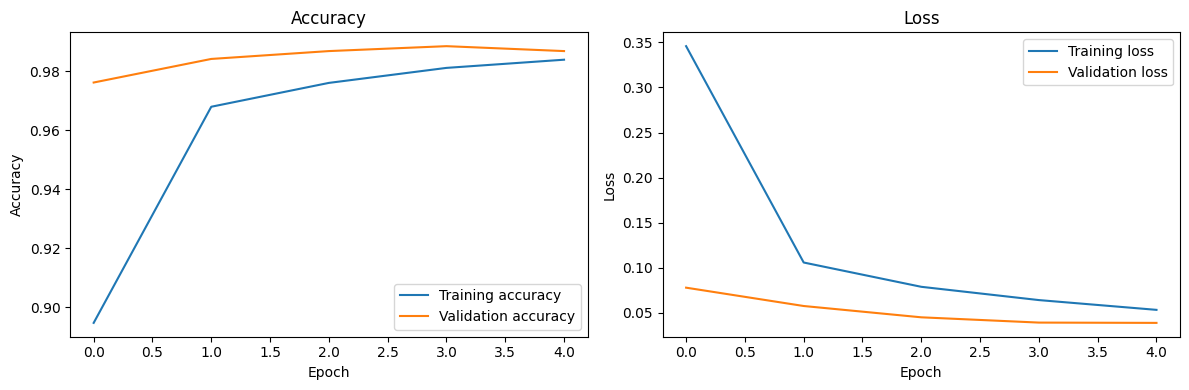

In [7]:
# Plot Training vs Validation Performance over Epochs
plt.figure(figsize=(12, 4))

# Subplot 1: Model Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy')

# Subplot 2: Model Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss')

plt.tight_layout()
plt.show()

## 8. Evaluate on test data

In [8]:
# Evaluate the model's final performance on the unseen test dataset
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

Test loss: 0.0315
Test accuracy: 98.93%


## 9. Predict sample digits

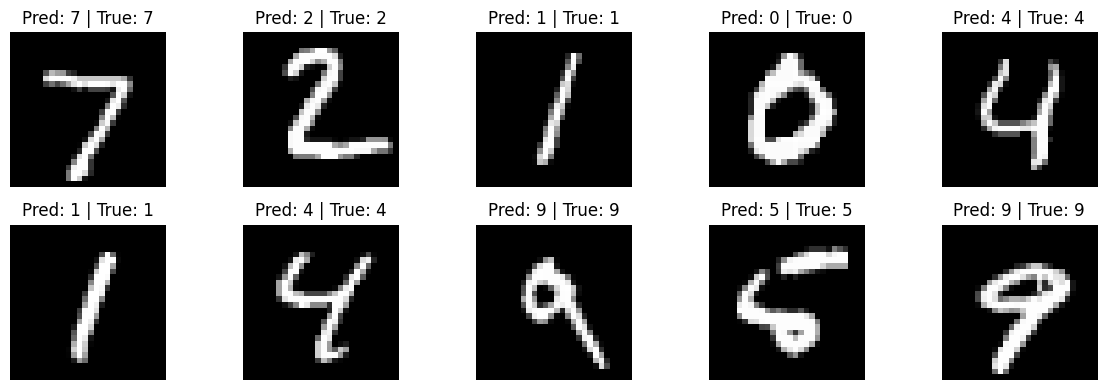

In [9]:
# Generate predictions for the first 10 test samples
probabilities = model.predict(x_test[:10], verbose=0)
predictions = np.argmax(probabilities, axis=1)  # Class with the highest probability

# Plot the 10 samples with their prediction and ground-truth values
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap='gray')  # Remove the redundant channel dimension
    plt.title(f'Pred: {predictions[i]} | True: {y_test[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 10. Confusion matrix and classification report

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       0.99      0.98      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



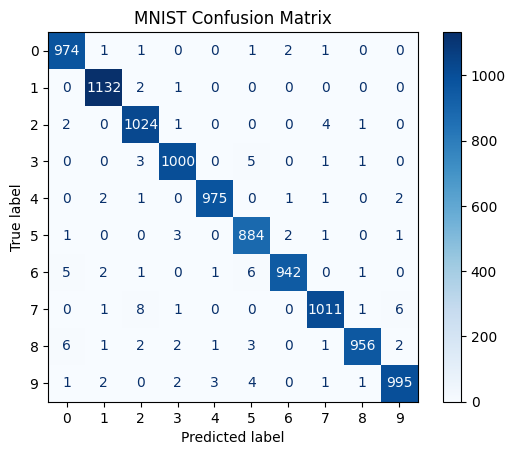

In [10]:
# Predict classes for the entire test set to evaluate precision and recall
all_predictions = np.argmax(model.predict(x_test, verbose=0), axis=1)

# Print a classification report (precision, recall, f1-score, support per digit)
print(classification_report(y_test, all_predictions))

# Compute and plot the Confusion Matrix
cm = confusion_matrix(y_test, all_predictions)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues', values_format='d')
plt.title('MNIST Confusion Matrix')
plt.show()

## 11. Save the trained model
The saved file can be loaded by the optional Streamlit application in this project.

In [11]:
# Save the entire model (architecture, weights, optimizer state) into Keras format
model.save('digit_cnn_model.keras')
print('Model saved as digit_cnn_model.keras')

# Trigger a download to save the model to your local machine from Google Colab
from google.colab import files
files.download('digit_cnn_model.keras')

Model saved as digit_cnn_model.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Try your own image
Upload a clear 28×28-compatible image containing one white/black digit. This cell converts it to grayscale, resizes it, and tries both common foreground polarities. You may need to adjust preprocessing for images unlike MNIST.

In [12]:
# Interactive Image Upload and Inference
from google.colab import files
from PIL import Image, ImageOps

# Prompt user to upload their own file
uploaded = files.upload()
if uploaded:
    filename = next(iter(uploaded))
    # Convert image to grayscale ('L') and resize to MNIST standards (28x28)
    img = Image.open(filename).convert('L').resize((28, 28))
    arr = np.array(img).astype('float32') / 255.0

    # Invert colors if foreground/background colors are reversed
    # MNIST usually has a dark background and bright digit.
    if arr.mean() > 0.5:
        arr = 1.0 - arr

    # Format array for prediction: shape must be (batch_size, height, width, channels)
    arr = arr.reshape(1, 28, 28, 1)

    # Run inference
    probs = model.predict(arr, verbose=0)[0]
    print('Predicted digit:', int(np.argmax(probs)))
    print('Confidence:', f'{np.max(probs) * 100:.2f}%')

    # Visualize how the model parsed the uploaded image
    plt.imshow(arr[0, :, :, 0], cmap='gray')
    plt.axis('off')
    plt.show()

KeyboardInterrupt: 